# Yeni toplama yöntemine geçelim mi?

Depoda A yönteminin yerine B öneriliyor. Yönetici sadece küçük p değil, iş başına en az 1 saniye iyileşme istiyor. Aynı 36 operatör her yöntemle 20 standart işi yapıyor; AB/BA sırası dengeli rastgele atanıyor. 1.440 ham satırın 1.440 bağımsız operatör olmadığını fark etmek analizin kritik adımı.

**Karar:** B yöntemini sınırlı pilotta sürdürmek için en az 1 saniyelik iyileşme kanıtı ve operasyonel uygulanabilirlik var mı?

**Birim:** Bağımsız birim: operatör. Ham gözlem: tek standart iş. Hedef: operatörlerin ortalama A−B süre farkı.

**Yöntem:** Her operatörün A ve B ortalamalarını çıkar. Operatör düzeyindeki eşli farkların ortalaması için t aralığı kur; doğal birimdeki aralığı önceden seçilmiş 1 saniye eşiğiyle karşılaştır. Ham satırları bağımsız sayma.

Veriler sabit tohumla üretilmiş sentetiktir; gerçek şirket veya kişi verisi değildir. Python paket sürümleri ZIP içindeki requirements.txt dosyasındadır. Her senaryo kendi verisini üretir; CSV dosyaları hazır örneklerle birlikte verilir.


## Senaryo: B yaklaşık 1,5 sn daha hızlı

Önce beklediğin sonucu yaz. Aşağıdaki hücre analizin tamamını içerir; seçilmiş senaryoyu değiştirip yeniden çalıştırabilirsin.


                           Ölçü                 Değer
     Bağımsız birim / ham satır 36 operatör / 1440 iş
                 A−B farkı · sn              1.556759
             Alt %95 sınır · sn              1.290773
             Üst %95 sınır · sn              1.822746
                    İki yönlü p                   0.0
12.000 işte eşdeğer süre · saat              5.189198

Sıra etkisi için ilk kontrol
sequence  count     mean      std
      AB     18 1.584151 0.781433
      BA     18 1.529367 0.812474

Karar: Aralığın alt sınırı 1 saniyenin üzerinde; bu sınırlı deneyde önceden seçilen önemli iyileşme eşiği destekleniyor.

Sınır: Kontrollü sentetik görev seti, dengeli rastgele AB/BA sırası ve operatörler arası bağımsızlık. Gerçek pilotta taşıma/öğrenme, ürün karışımı, tempo ve tolerans ayrıca değerlendirilir; ölçülen çevrim süresi standart zaman değildir.


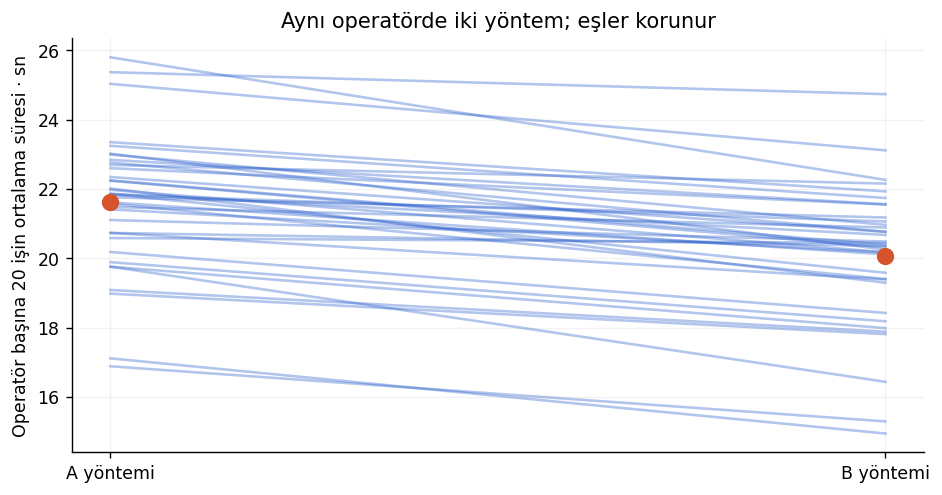

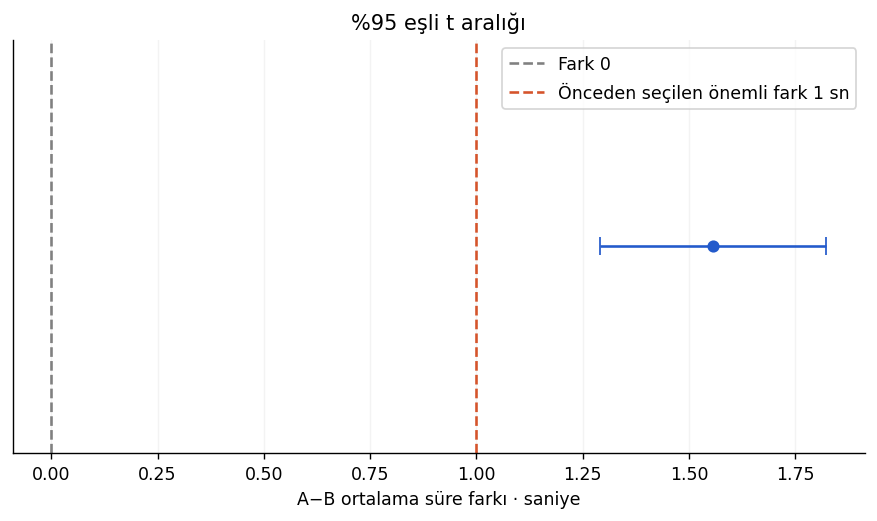

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
plt.rcParams.update({'figure.figsize':(8.8,4.3),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

def tbl(df,title):return {'title':title,'columns':[str(c) for c in df.columns],'rows':df.where(pd.notnull(df),None).values.tolist()}

def picking(scenario='default'):
 rng=np.random.default_rng(260801);n=36;sequence=np.array(['AB']*18+['BA']*18);rng.shuffle(sequence);rows=[];effect=1.5 if scenario=='default' else .35
 for worker in range(n):
  baseline=rng.normal(22,2);individual=effect+rng.normal(0,.45)
  for method in ['A','B']:
   second=(sequence[worker]=='AB' and method=='B')or(sequence[worker]=='BA'and method=='A')
   for trial in range(1,21):rows.append([worker+1,sequence[worker],method,trial,baseline-(individual if method=='B' else 0)-(.2 if second else 0)+rng.normal(0,2.4)])
 raw=pd.DataFrame(rows,columns=['operator','sequence','method','trial','seconds']);means=raw.groupby(['operator','sequence','method']).seconds.mean().unstack('method').reset_index();diff=means.A-means.B;n=len(diff);mean=diff.mean();se=stats.sem(diff);ci=stats.t.interval(.95,n-1,loc=mean,scale=se);test=stats.ttest_rel(means.A,means.B);important=1.;volume=12000
 assert len(raw)==1440 and means.shape[0]==36
 fig,ax=plt.subplots();ax.plot([0,1],np.vstack([means.A,means.B]),alpha=.35,color='#235ACB');ax.scatter([0,1],[means.A.mean(),means.B.mean()],c='#D5542B',s=80,zorder=3);ax.set(xticks=[0,1],xticklabels=['A yöntemi','B yöntemi'],ylabel='Operatör başına 20 işin ortalama süresi · sn',title='Aynı operatörde iki yöntem; eşler korunur')
 fig2,ax2=plt.subplots();ax2.errorbar([mean],[1],xerr=[[mean-ci[0]],[ci[1]-mean]],fmt='o',color='#235ACB',capsize=5);ax2.axvline(0,color='gray',ls='--',label='Fark 0');ax2.axvline(important,color='#D5542B',ls='--',label='Önceden seçilen önemli fark 1 sn');ax2.set(yticks=[],xlabel='A−B ortalama süre farkı · saniye',title='%95 eşli t aralığı');ax2.legend()
 order=means.assign(difference=diff).groupby('sequence').difference.agg(['count','mean','std']).reset_index();decision='Aralığın alt sınırı 1 saniyenin üzerinde; bu sınırlı deneyde önceden seçilen önemli iyileşme eşiği destekleniyor.' if ci[0]>important else 'Aralık önemli iyileşme eşiğinin üstünde kalmıyor; küçük p olsa bile en az 1 saniye kazanç iddiası desteklenmiş sayılmaz.'
 return dict(metrics={'Bağımsız birim / ham satır':f'{n} operatör / {len(raw)} iş','A−B farkı · sn':mean,'Alt %95 sınır · sn':ci[0],'Üst %95 sınır · sn':ci[1],'İki yönlü p':test.pvalue,'12.000 işte eşdeğer süre · saat':volume*mean/3600},tables=[tbl(order,'Sıra etkisi için ilk kontrol')],figures=[('Her çizgi aynı operatörün A ve B ortalamalarını bağlar.',fig),('Sıfır ve önceden belirlenen 1 saniyelik iş eşiği ayrı okunur.',fig2)],frames={'ham_isler':raw,'operator_ortalamalari':means},steps=[f'Her operatör ve yöntem için 20 ölçümü ortala; {n} eşli fark oluştur.',f'Fark ortalaması {mean:.3f}; SE={se:.3f}; df={n-1}. Ortalama ± t×SE aralığını kur.',f'İş yükü dönüşümü: 12.000 × {mean:.3f} / 3.600 saat. Bu bir süre eşdeğeridir, otomatik personel azaltma değildir.'],decision=decision,diagnostics={'randomized_sequences':sequence.tolist(),'independent_n':n,'raw_n':len(raw),'minimum_important_difference':important,'ci':[float(ci[0]),float(ci[1])],'mean_difference':mean,'p':test.pvalue},limit='Kontrollü sentetik görev seti, dengeli rastgele AB/BA sırası ve operatörler arası bağımsızlık. Gerçek pilotta taşıma/öğrenme, ürün karışımı, tempo ve tolerans ayrıca değerlendirilir; ölçülen çevrim süresi standart zaman değildir.')

result=picking('default')
print(pd.DataFrame(list(result['metrics'].items()),columns=['Olcu','Deger']).to_string(index=False))
for t in result['tables']: print(t['title']); print(pd.DataFrame(t['rows'],columns=t['columns']).to_string(index=False))
print('Karar:', result['decision']); print('Sinir:',result['limit'])
for caption,fig in result['figures']: print(caption); plt.show()


## Senaryo: B yalnız yaklaşık 0,35 sn daha hızlı

Önce beklediğin sonucu yaz. Aşağıdaki hücre analizin tamamını içerir; seçilmiş senaryoyu değiştirip yeniden çalıştırabilirsin.


                           Ölçü                 Değer
     Bağımsız birim / ham satır 36 operatör / 1440 iş
                 A−B farkı · sn              0.406759
             Alt %95 sınır · sn              0.140773
             Üst %95 sınır · sn              0.672746
                    İki yönlü p              0.003762
12.000 işte eşdeğer süre · saat              1.355864

Sıra etkisi için ilk kontrol
sequence  count     mean      std
      AB     18 0.434151 0.781433
      BA     18 0.379367 0.812474

Karar: Aralık önemli iyileşme eşiğinin üstünde kalmıyor; küçük p olsa bile en az 1 saniye kazanç iddiası desteklenmiş sayılmaz.

Sınır: Kontrollü sentetik görev seti, dengeli rastgele AB/BA sırası ve operatörler arası bağımsızlık. Gerçek pilotta taşıma/öğrenme, ürün karışımı, tempo ve tolerans ayrıca değerlendirilir; ölçülen çevrim süresi standart zaman değildir.


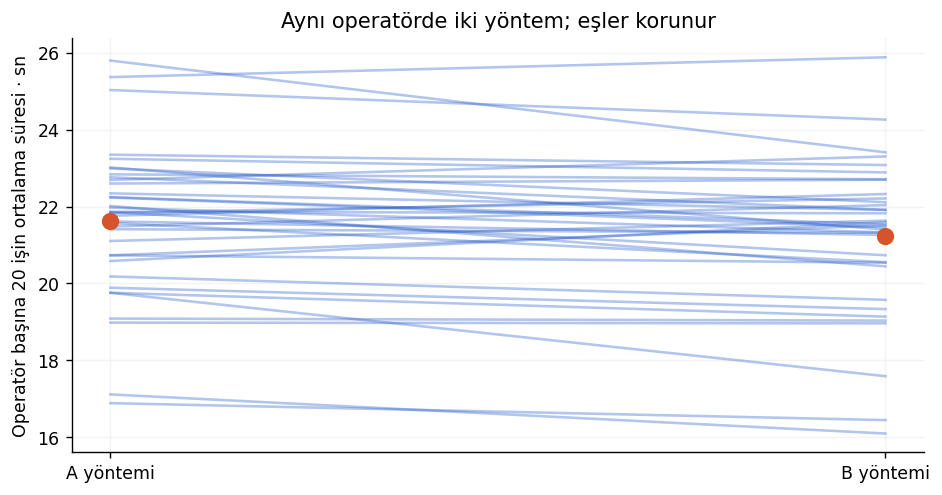

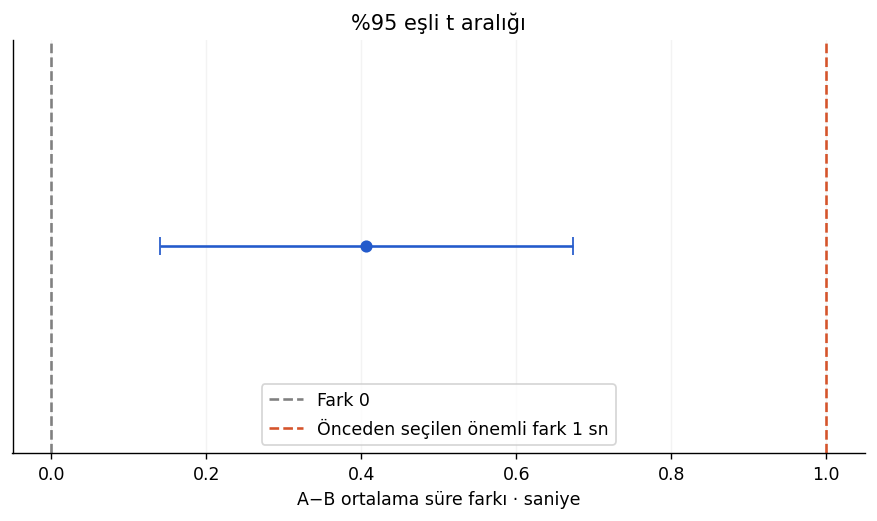

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, special
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.statespace.sarimax import SARIMAX
plt.rcParams.update({'figure.figsize':(8.8,4.3),'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':.15})

def tbl(df,title):return {'title':title,'columns':[str(c) for c in df.columns],'rows':df.where(pd.notnull(df),None).values.tolist()}

def picking(scenario='default'):
 rng=np.random.default_rng(260801);n=36;sequence=np.array(['AB']*18+['BA']*18);rng.shuffle(sequence);rows=[];effect=1.5 if scenario=='default' else .35
 for worker in range(n):
  baseline=rng.normal(22,2);individual=effect+rng.normal(0,.45)
  for method in ['A','B']:
   second=(sequence[worker]=='AB' and method=='B')or(sequence[worker]=='BA'and method=='A')
   for trial in range(1,21):rows.append([worker+1,sequence[worker],method,trial,baseline-(individual if method=='B' else 0)-(.2 if second else 0)+rng.normal(0,2.4)])
 raw=pd.DataFrame(rows,columns=['operator','sequence','method','trial','seconds']);means=raw.groupby(['operator','sequence','method']).seconds.mean().unstack('method').reset_index();diff=means.A-means.B;n=len(diff);mean=diff.mean();se=stats.sem(diff);ci=stats.t.interval(.95,n-1,loc=mean,scale=se);test=stats.ttest_rel(means.A,means.B);important=1.;volume=12000
 assert len(raw)==1440 and means.shape[0]==36
 fig,ax=plt.subplots();ax.plot([0,1],np.vstack([means.A,means.B]),alpha=.35,color='#235ACB');ax.scatter([0,1],[means.A.mean(),means.B.mean()],c='#D5542B',s=80,zorder=3);ax.set(xticks=[0,1],xticklabels=['A yöntemi','B yöntemi'],ylabel='Operatör başına 20 işin ortalama süresi · sn',title='Aynı operatörde iki yöntem; eşler korunur')
 fig2,ax2=plt.subplots();ax2.errorbar([mean],[1],xerr=[[mean-ci[0]],[ci[1]-mean]],fmt='o',color='#235ACB',capsize=5);ax2.axvline(0,color='gray',ls='--',label='Fark 0');ax2.axvline(important,color='#D5542B',ls='--',label='Önceden seçilen önemli fark 1 sn');ax2.set(yticks=[],xlabel='A−B ortalama süre farkı · saniye',title='%95 eşli t aralığı');ax2.legend()
 order=means.assign(difference=diff).groupby('sequence').difference.agg(['count','mean','std']).reset_index();decision='Aralığın alt sınırı 1 saniyenin üzerinde; bu sınırlı deneyde önceden seçilen önemli iyileşme eşiği destekleniyor.' if ci[0]>important else 'Aralık önemli iyileşme eşiğinin üstünde kalmıyor; küçük p olsa bile en az 1 saniye kazanç iddiası desteklenmiş sayılmaz.'
 return dict(metrics={'Bağımsız birim / ham satır':f'{n} operatör / {len(raw)} iş','A−B farkı · sn':mean,'Alt %95 sınır · sn':ci[0],'Üst %95 sınır · sn':ci[1],'İki yönlü p':test.pvalue,'12.000 işte eşdeğer süre · saat':volume*mean/3600},tables=[tbl(order,'Sıra etkisi için ilk kontrol')],figures=[('Her çizgi aynı operatörün A ve B ortalamalarını bağlar.',fig),('Sıfır ve önceden belirlenen 1 saniyelik iş eşiği ayrı okunur.',fig2)],frames={'ham_isler':raw,'operator_ortalamalari':means},steps=[f'Her operatör ve yöntem için 20 ölçümü ortala; {n} eşli fark oluştur.',f'Fark ortalaması {mean:.3f}; SE={se:.3f}; df={n-1}. Ortalama ± t×SE aralığını kur.',f'İş yükü dönüşümü: 12.000 × {mean:.3f} / 3.600 saat. Bu bir süre eşdeğeridir, otomatik personel azaltma değildir.'],decision=decision,diagnostics={'randomized_sequences':sequence.tolist(),'independent_n':n,'raw_n':len(raw),'minimum_important_difference':important,'ci':[float(ci[0]),float(ci[1])],'mean_difference':mean,'p':test.pvalue},limit='Kontrollü sentetik görev seti, dengeli rastgele AB/BA sırası ve operatörler arası bağımsızlık. Gerçek pilotta taşıma/öğrenme, ürün karışımı, tempo ve tolerans ayrıca değerlendirilir; ölçülen çevrim süresi standart zaman değildir.')

result=picking('small')
print(pd.DataFrame(list(result['metrics'].items()),columns=['Olcu','Deger']).to_string(index=False))
for t in result['tables']: print(t['title']); print(pd.DataFrame(t['rows'],columns=t['columns']).to_string(index=False))
print('Karar:', result['decision']); print('Sinir:',result['limit'])
for caption,fig in result['figures']: print(caption); plt.show()


## Uygula ve karar notu

Küçük etki senaryosuna geç. p ile 1 saniyelik iş eşiğinin farklı kararlar verebildiğini aralıktan göster.

Kabul ölçütleri: analiz birimini doğru tanımla; yöntem seçimini gerekçelendir; etkiyi/aralığı doğal birimle raporla; varsayımı ve bir sonraki veri ihtiyacını yaz.
